In [1]:
import torch
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles

In [2]:
n_samples = 1000

X, y = make_circles(
    n_samples=n_samples,
    noise=0.03,
    random_state=42
)

In [3]:
print("First five X values:")
print(X[:5])

First five X values:
[[ 0.75424625  0.23148074]
 [-0.75615888  0.15325888]
 [-0.81539193  0.17328203]
 [-0.39373073  0.69288277]
 [ 0.44220765 -0.89672343]]


In [4]:
print("First five y values:")
print(y[:5])

First five y values:
[1 1 1 1 0]


In [5]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1000, 2)
y shape: (1000,)


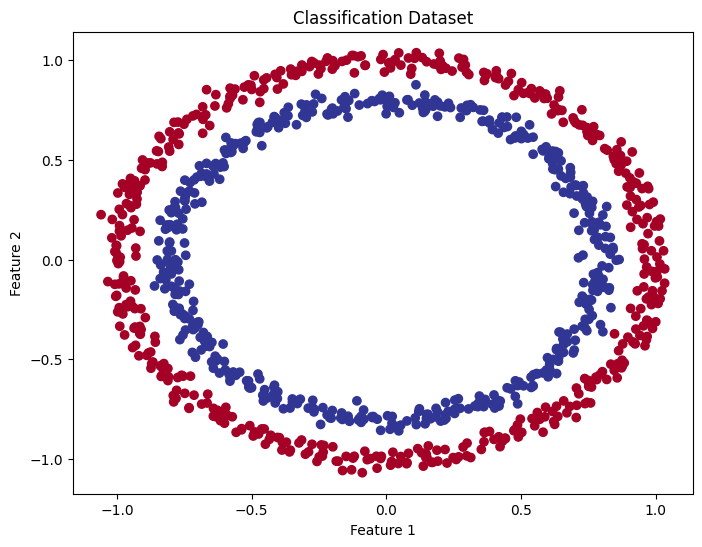

In [8]:
plt.figure(figsize=(8, 6))
plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap=plt.cm.RdYlBu
)
plt.title("Classification Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [9]:
X = torch.from_numpy(X).type(torch.float32)
y = torch.from_numpy(y).type(torch.float32)

In [10]:
print("X tensor:", X[:5])
print("y tensor:", y[:5])

X tensor: tensor([[ 0.7542,  0.2315],
        [-0.7562,  0.1533],
        [-0.8154,  0.1733],
        [-0.3937,  0.6929],
        [ 0.4422, -0.8967]])
y tensor: tensor([1., 1., 1., 1., 0.])


In [11]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: torch.Size([1000, 2])
y shape: torch.Size([1000])


In [12]:
train_split = int(0.8 * len(X))
X_train = X[:train_split]
y_train = y[:train_split]
X_test = X[train_split:]
y_test = y[train_split:]
print("training samples:", len(X_train))
print("testing samples:", len(X_test))


training samples: 800
testing samples: 200


In [14]:
from torch import nn
torch.manual_seed(42)
class CircleModelV0(nn.Module):
    def __init__(self):
        super().__init__()

        self.layer_1 = nn.Linear(
            in_features=2,
            out_features=5
        )

        self.layer_2 = nn.Linear(
            in_features=5,
            out_features=1
        )

    def forward(self, x):
        return self.layer_2(self.layer_1(x))


model = CircleModelV0()
print("Model:")
print(model)

Model:
CircleModelV0(
  (layer_1): Linear(in_features=2, out_features=5, bias=True)
  (layer_2): Linear(in_features=5, out_features=1, bias=True)
)


In [15]:
print("Model parameters:")
for parameter in model.parameters():
    print(parameter.shape)


Model parameters:
torch.Size([5, 2])
torch.Size([5])
torch.Size([1, 5])
torch.Size([1])


In [16]:
with torch.inference_mode():
    y_logits = model(X_test[:5])
print("\nFirst five raw outputs:")
print(y_logits)
print("Output shape:", y_logits.shape)


First five raw outputs:
tensor([[-0.0946],
        [-0.1374],
        [-0.0939],
        [-0.1950],
        [-0.0847]])
Output shape: torch.Size([5, 1])


In [17]:
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(
    params=model.parameters(),
    lr=0.1
)
y_logits = model(X_train).squeeze()
loss = loss_fn(y_logits, y_train)
print("initial training loss:", loss.item())

initial training loss: 0.6956290602684021


In [18]:
torch.manual_seed(42)
epochs = 100
for epoch in range(epochs):
    model.train()
    y_logits = model(X_train).squeeze()
    loss = loss_fn(y_logits, y_train)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    model.eval()
    with torch.inference_mode():
        test_logits = model(X_test).squeeze()
        test_loss = loss_fn(test_logits, y_test)
    if epoch % 10 == 0:
        print(
            f"Epoch: {epoch} | "
            f"Train loss: {loss.item():.4f} | "
            f"Test loss: {test_loss.item():.4f}"
        )

Epoch: 0 | Train loss: 0.6956 | Test loss: 0.6975
Epoch: 10 | Train loss: 0.6937 | Test loss: 0.6973
Epoch: 20 | Train loss: 0.6930 | Test loss: 0.6977
Epoch: 30 | Train loss: 0.6927 | Test loss: 0.6980
Epoch: 40 | Train loss: 0.6926 | Test loss: 0.6984
Epoch: 50 | Train loss: 0.6925 | Test loss: 0.6986
Epoch: 60 | Train loss: 0.6925 | Test loss: 0.6988
Epoch: 70 | Train loss: 0.6925 | Test loss: 0.6989
Epoch: 80 | Train loss: 0.6925 | Test loss: 0.6990
Epoch: 90 | Train loss: 0.6925 | Test loss: 0.6991


In [19]:
model.eval()
with torch.inference_mode():
    y_logits = model(X_test).squeeze()
    y_probs = torch.sigmoid(y_logits)
    y_preds = torch.round(y_probs)
print("first 10 logits:")
print(y_logits[:10])


first 10 logits:
tensor([ 0.0873,  0.0603,  0.0721, -0.0809,  0.0826, -0.0968, -0.0506, -0.0081,
         0.0918,  0.1134])


In [20]:
print("First 10 probab:")
print(y_probs[:10])


First 10 probab:
tensor([0.5218, 0.5151, 0.5180, 0.4798, 0.5206, 0.4758, 0.4874, 0.4980, 0.5229,
        0.5283])


In [21]:
print("First 10 predictions:")
print(y_preds[:10])


First 10 predictions:
tensor([1., 1., 1., 0., 1., 0., 0., 0., 1., 1.])


In [22]:
print("First 10 actual labels:")
print(y_test[:10])

First 10 actual labels:
tensor([1., 1., 1., 1., 0., 0., 1., 0., 1., 0.])


In [23]:
correct_predictions = torch.eq(y_preds, y_test).sum().item()
accuracy = (correct_predictions / len(y_test)) * 100
print(f"\nTest accuracy: {accuracy:.2f}%")


Test accuracy: 43.50%


In [24]:
class CircleModelV1(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1 = nn.Linear(2, 10)
        self.layer_2 = nn.Linear(10, 10)
        self.layer_3 = nn.Linear(10, 1)
        self.relu = nn.ReLU()
    def forward(self, x):
        x = self.relu(self.layer_1(x))
        x = self.relu(self.layer_2(x))
        x = self.layer_3(x)
        return x

In [25]:
torch.manual_seed(42)
model = CircleModelV1()
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(
    params=model.parameters(),
    lr=0.1
)
epochs = 300
for epoch in range(epochs):
    model.train()
    y_logits = model(X_train).squeeze()
    loss = loss_fn(y_logits, y_train)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    model.eval()
    with torch.inference_mode():
        test_logits = model(X_test).squeeze()
        test_loss = loss_fn(test_logits, y_test)
        test_preds = torch.round(torch.sigmoid(test_logits))
        accuracy = (
            torch.eq(test_preds, y_test).sum().item()
            / len(y_test)
        ) * 100
    if epoch % 50 == 0:
        print(
            f"Epoch: {epoch} | "
            f"Train loss: {loss.item():.4f} | "
            f"Test loss: {test_loss.item():.4f} | "
            f"Accuracy: {accuracy:.2f}%"
        )

Epoch: 0 | Train loss: 0.6929 | Test loss: 0.6936 | Accuracy: 49.50%
Epoch: 50 | Train loss: 0.6918 | Test loss: 0.6920 | Accuracy: 66.50%
Epoch: 100 | Train loss: 0.6912 | Test loss: 0.6911 | Accuracy: 58.00%
Epoch: 150 | Train loss: 0.6907 | Test loss: 0.6903 | Accuracy: 57.50%
Epoch: 200 | Train loss: 0.6900 | Test loss: 0.6894 | Accuracy: 60.00%
Epoch: 250 | Train loss: 0.6893 | Test loss: 0.6884 | Accuracy: 59.50%


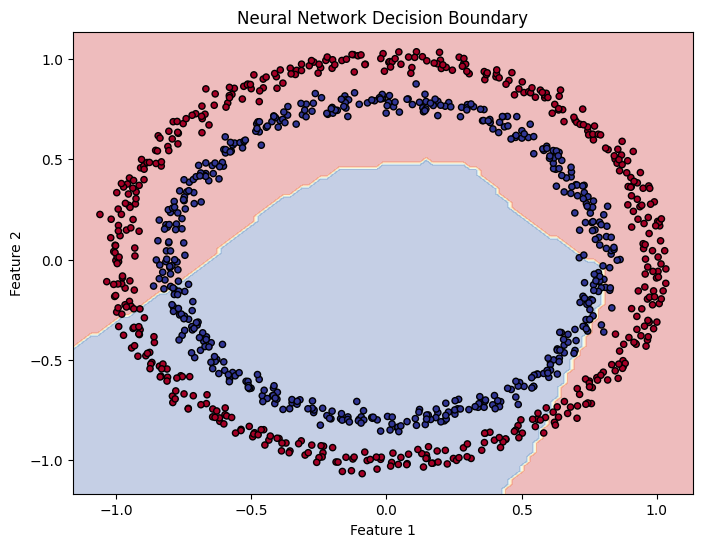

In [26]:
import numpy as np
def plot_decision_boundary(model, X, y):
    X = X.detach().cpu().numpy()
    y = y.detach().cpu().numpy()
    x_min, x_max = X[:, 0].min() - 0.1, X[:, 0].max() + 0.1
    y_min, y_max = X[:, 1].min() - 0.1, X[:, 1].max() + 0.1
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 101),
        np.linspace(y_min, y_max, 101)
    )
    grid = np.column_stack((xx.ravel(), yy.ravel()))
    grid_tensor = torch.tensor(grid, dtype=torch.float32)
    model.eval()
    with torch.inference_mode():
        logits = model(grid_tensor).squeeze()
        predictions = torch.round(torch.sigmoid(logits))

    predictions = predictions.reshape(xx.shape).numpy()
    plt.figure(figsize=(8, 6))
    plt.contourf(
        xx, yy, predictions,
        alpha=0.3,
        cmap=plt.cm.RdYlBu
    )
    plt.scatter(
        X[:, 0], X[:, 1],
        c=y,
        cmap=plt.cm.RdYlBu,
        edgecolors="black",
        s=20
    )
    plt.title("Neural Network Decision Boundary")
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.show()

plot_decision_boundary(model, X, y)


In [27]:
model.eval()
with torch.inference_mode():
    train_logits = model(X_train).squeeze()
    train_preds = torch.round(torch.sigmoid(train_logits))
    test_logits = model(X_test).squeeze()
    test_preds = torch.round(torch.sigmoid(test_logits))
    train_accuracy = (
        (train_preds == y_train).float().mean() * 100
    )
    test_accuracy = (
        (test_preds == y_test).float().mean() * 100
    )
print(f"Final training accuracy: {train_accuracy.item():.2f}%")
print(f"Final testing accuracy: {test_accuracy.item():.2f}%")

Final training accuracy: 56.63%
Final testing accuracy: 60.50%
